In [3]:
import numpy as np
from scipy.optimize import curve_fit, least_squares
import matplotlib.pyplot as plt
import statsmodels.api as sm
import pandas as pd
from IPython.display import Latex
import scipy.signal
from scipy.signal import find_peaks

In [4]:
df = pd.read_csv('dopplerDat.csv')

In [6]:
df

,Time (s),Ax (m/s²),Ay (m/s²),Az (m/s²),Intensity
0,0.01,0.278366,0.023440,-9.484516,8.173249
1,0.02,0.306563,0.029296,-9.482180,8.173249
2,0.03,0.414755,0.011133,-9.424316,8.174082
3,0.04,0.442770,0.012323,-9.356950,8.174082
4,0.05,0.379742,-0.032794,-9.324190,8.173999
...,...,...,...,...,...
745,7.46,6.435901,-12.258953,-15.907359,4.000768
746,7.47,6.333101,-11.398993,-15.645958,4.014295
747,7.48,4.923682,-11.499918,-14.945657,4.012905
748,7.49,3.301795,-11.940831,-13.841187,4.000300


[0.66879799]
[42.5292968  42.62695305 42.57812493 42.7246093 ]
0.010000000017371117


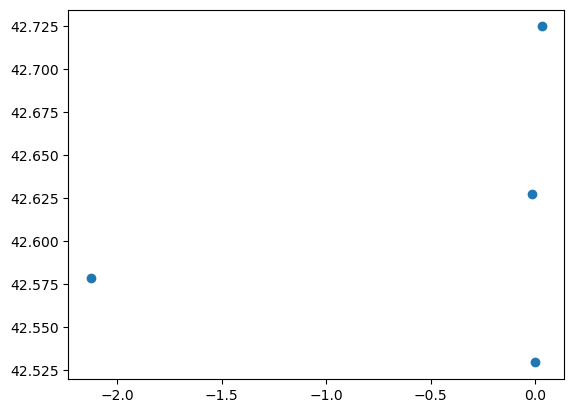

In [27]:
# Data from 1

freq_emitted = 600 # Hz

time = df['Time (s)'].to_numpy()[100:-100]
intensity = df['Intensity'].to_numpy()[100:-100]
acceleration = df['Ay (m/s²)'].to_numpy()[100:-100]
v_dat = scipy.integrate.cumulative_trapezoid(acceleration - np.mean(acceleration), initial=0, x=time)


sampling_freq = 1 / np.mean(np.diff(time))
f, t, zxx = scipy.signal.stft(intensity - np.mean(intensity), fs=sampling_freq, nperseg=512, nfft=2048)
peak_freq_indices = np.argmax(np.abs(zxx), axis=0)
freq1 = f[peak_freq_indices]

v_interp = np.interp(t + time[0], time, v_dat)

# Doppler Model
def doppler_freq(v, v_sound): 
    return freq_emitted * (v_sound / (-v + v_sound))

params, error = curve_fit(doppler_freq, v_interp, freq1, p0=[343])

print(params)
print(freq1)
print(np.mean(np.diff(time)))
plt.scatter(v_interp, freq1)